In [1]:
import os
import urllib.request

CSV_YOLU = "data/auto_mpg.csv"
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, CSV_YOLU)
    print("Veri seti indirildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/auto_mpg.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0000,8,307.0000,130.0000,3504,12.0000,70,usa,chevrolet chevelle malibu
1,15.0000,8,350.0000,165.0000,3693,11.5000,70,usa,buick skylark 320
2,18.0000,8,318.0000,150.0000,3436,11.0000,70,usa,plymouth satellite
3,16.0000,8,304.0000,150.0000,3433,12.0000,70,usa,amc rebel sst
4,17.0000,8,302.0000,140.0000,3449,10.5000,70,usa,ford torino
5,15.0000,8,429.0000,198.0000,4341,10.0000,70,usa,ford galaxie 500
6,14.0000,8,454.0000,220.0000,4354,9.0000,70,usa,chevrolet impala
7,14.0000,8,440.0000,215.0000,4312,8.5000,70,usa,plymouth fury iii
8,14.0000,8,455.0000,225.0000,4425,10.0000,70,usa,pontiac catalina
9,15.0000,8,390.0000,190.0000,3850,8.5000,70,usa,amc ambassador dpl


In [3]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
393,27.0000,4,140.0000,86.0000,2790,15.6000,82,usa,ford mustang gl
394,44.0000,4,97.0000,52.0000,2130,24.6000,82,europe,vw pickup
395,32.0000,4,135.0000,84.0000,2295,11.6000,82,usa,dodge rampage
396,28.0000,4,120.0000,79.0000,2625,18.6000,82,usa,ford ranger
397,31.0000,4,119.0000,82.0000,2720,19.4000,82,usa,chevy s-10


In [4]:
print(f"Gözlem sayısı  : {df.shape[0]}")
print(f"Değişken sayısı: {df.shape[1]}")
print()
df.info()

Gözlem sayısı  : 398
Değişken sayısı: 9

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [5]:
sayisal = df.select_dtypes(include="number").columns.tolist()
kategorik = df.select_dtypes(exclude="number").columns.tolist()
print("Sayısal değişkenler  :", sayisal)
print("Kategorik değişkenler:", kategorik)

Sayısal değişkenler  : ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Kategorik değişkenler: ['origin', 'name']


In [6]:
pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Eksik Oranı (%)": (df.isna().mean() * 100).round(2),
    "Benzersiz Değer": df.nunique(),
})

,Eksik Sayısı,Eksik Oranı (%),Benzersiz Değer
mpg,0,0.0000,129
cylinders,0,0.0000,5
displacement,0,0.0000,82
horsepower,6,1.5100,93
weight,0,0.0000,351
acceleration,0,0.0000,95
model_year,0,0.0000,13
origin,0,0.0000,3
name,0,0.0000,305


In [7]:
print("Tekrarlanan satır sayısı:", df.duplicated().sum())
df[df["horsepower"].isna()]

Tekrarlanan satır sayısı: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0000,4,98.0000,NaN,2046,19.0000,71,usa,ford pinto
126,21.0000,6,200.0000,NaN,2875,17.0000,74,usa,ford maverick
330,40.9000,4,85.0000,NaN,1835,17.3000,80,europe,renault lecar deluxe
336,23.6000,4,140.0000,NaN,2905,14.3000,80,usa,ford mustang cobra
354,34.5000,4,100.0000,NaN,2320,15.8000,81,europe,renault 18i
374,23.0000,4,151.0000,NaN,3035,20.5000,82,usa,amc concord dl


In [8]:
veri = df.dropna(subset=["horsepower"]).reset_index(drop=True)
print("Temizlenmiş veri boyutu:", veri.shape)

Temizlenmiş veri boyutu: (392, 9)


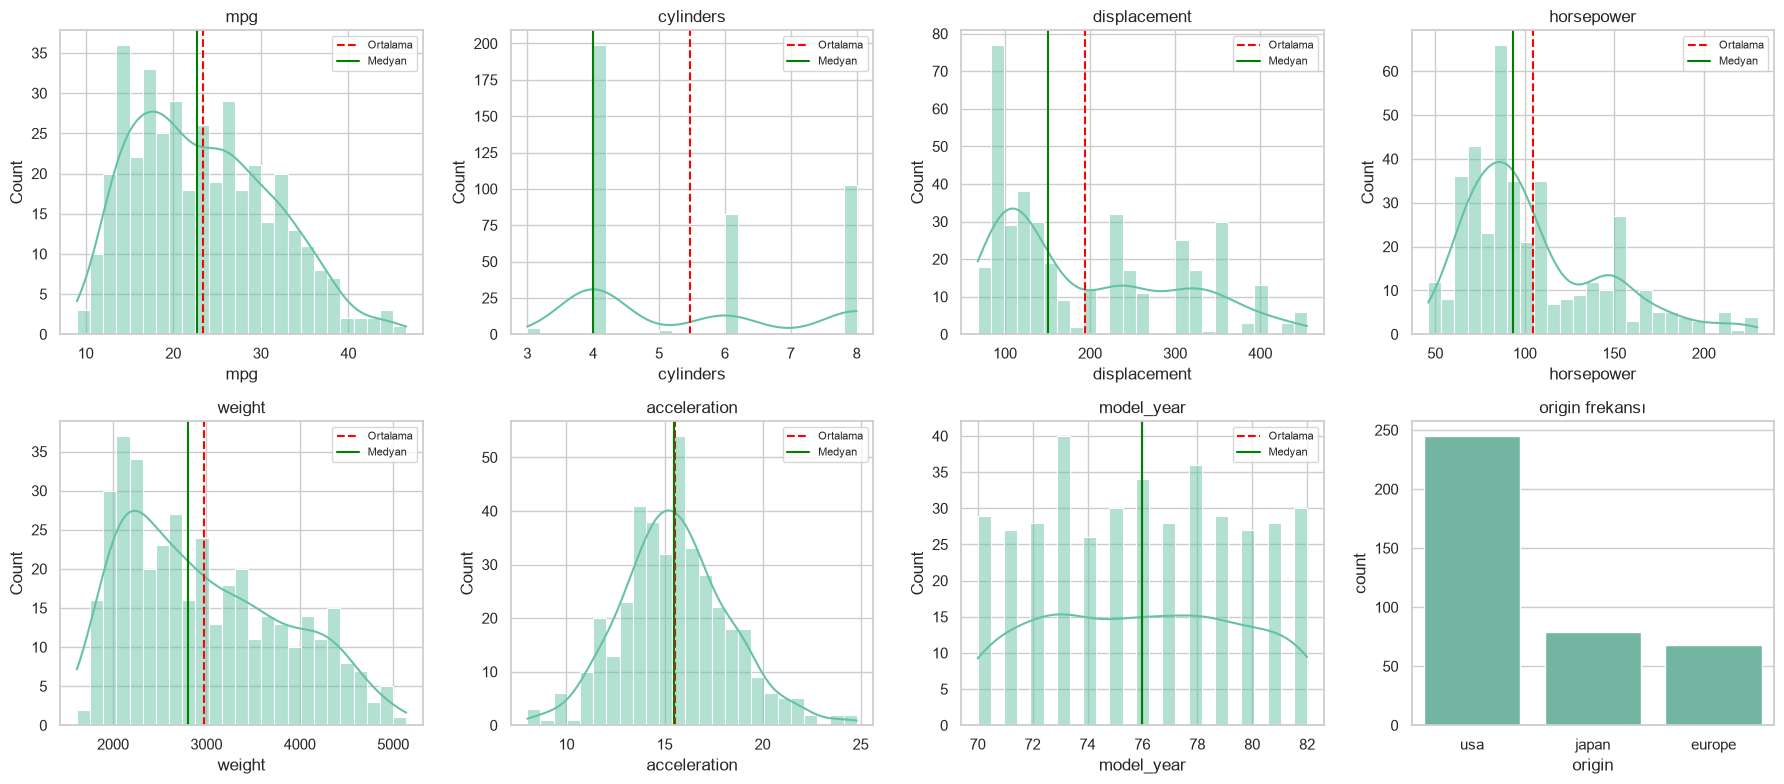

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, kol in zip(axes.flat, sayisal):
    sns.histplot(veri[kol], kde=True, ax=ax, bins=25)
    ax.axvline(veri[kol].mean(), color="red", linestyle="--", label="Ortalama")
    ax.axvline(veri[kol].median(), color="green", label="Medyan")
    ax.set_title(kol)
    ax.legend(fontsize=8)
sns.countplot(data=veri, x="origin", ax=axes.flat[-1])
axes.flat[-1].set_title("origin frekansı")
plt.tight_layout()
plt.show()

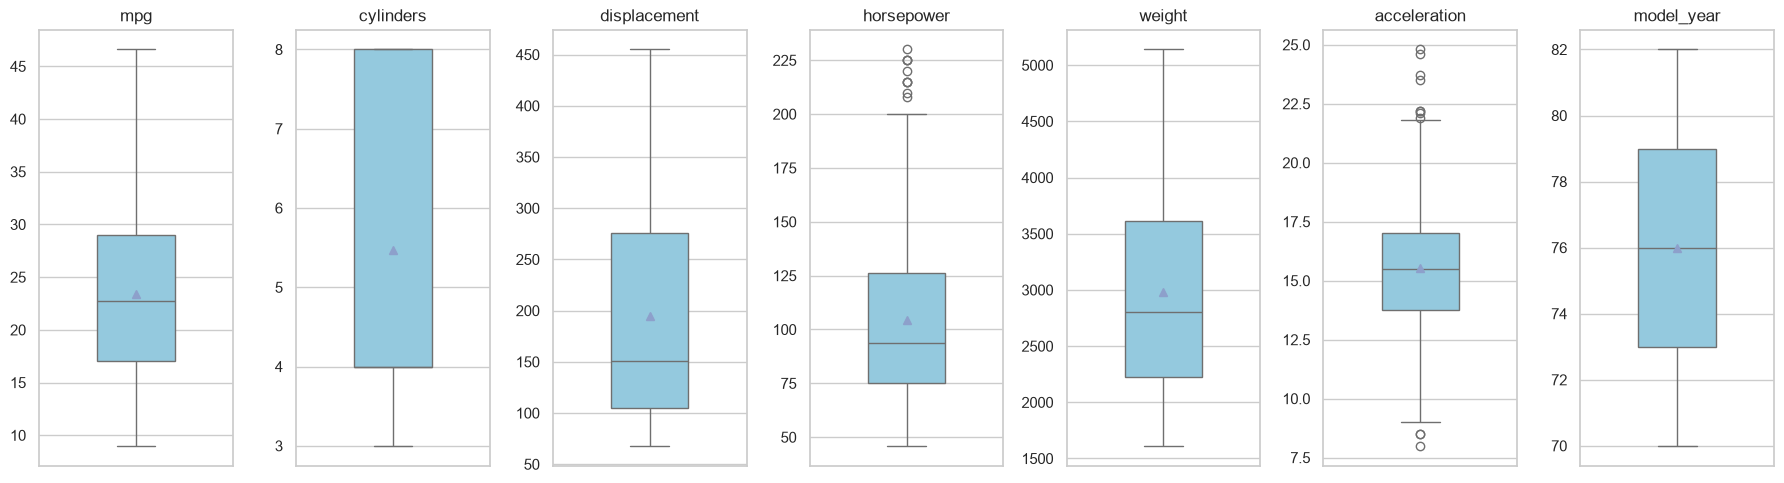

In [10]:
fig, axes = plt.subplots(1, len(sayisal), figsize=(18, 5))
for ax, kol in zip(axes, sayisal):
    sns.boxplot(y=veri[kol], ax=ax, color="skyblue", width=0.4, showmeans=True)
    ax.set_title(kol)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

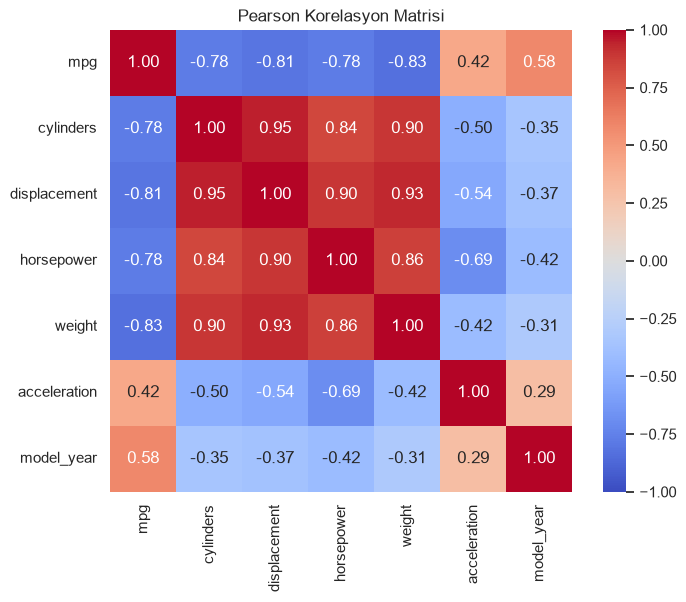

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(veri[sayisal].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Korelasyon Matrisi")
plt.show()

In [12]:
veri[sayisal].corr()["mpg"].drop("mpg").sort_values().to_frame("mpg ile korelasyon")

,mpg ile korelasyon
weight,-0.8322
displacement,-0.8051
horsepower,-0.7784
cylinders,-0.7776
acceleration,0.4233
model_year,0.5805


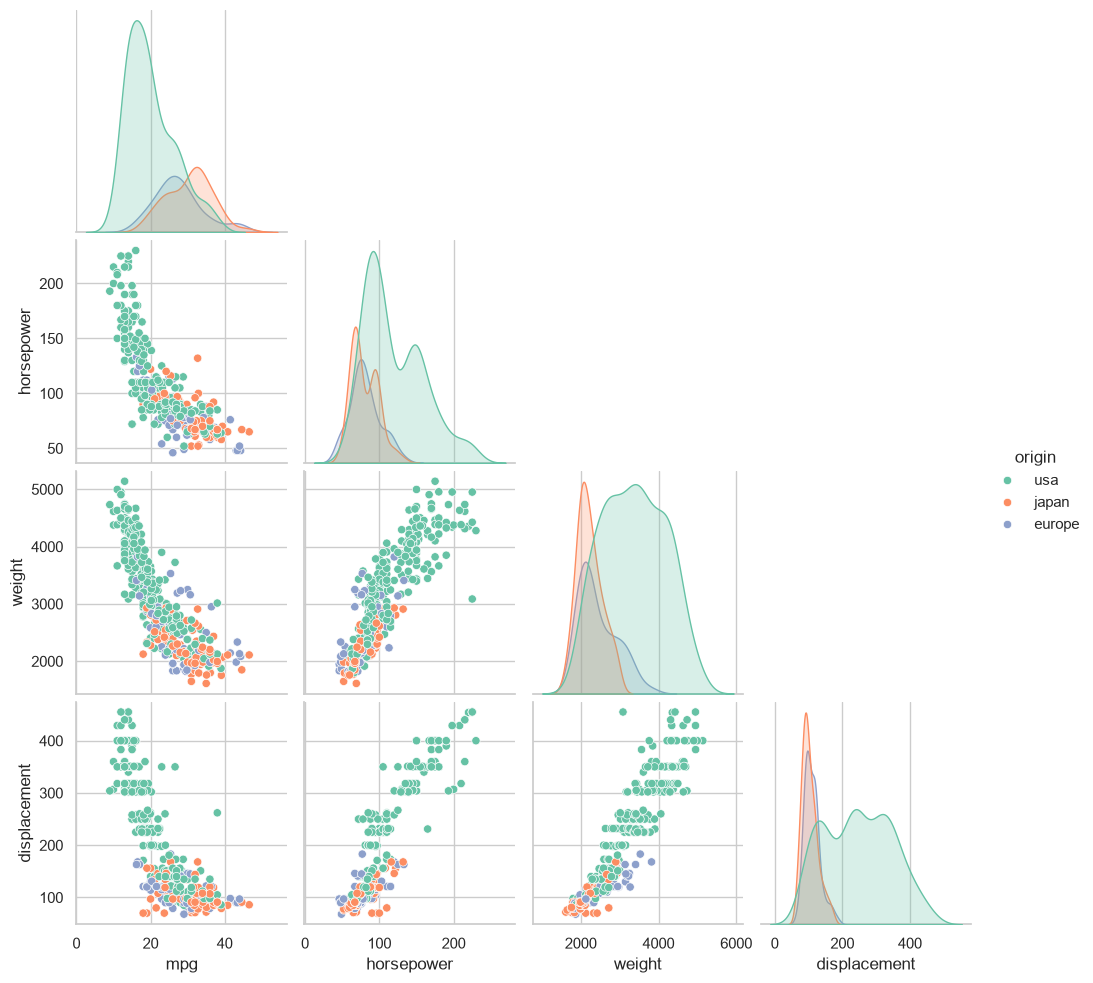

In [13]:
sns.pairplot(veri, vars=["mpg", "horsepower", "weight", "displacement"], hue="origin", corner=True)
plt.show()

In [14]:
veri.describe().T

,count,mean,std,min,25%,50%,75%,max
mpg,392.0000,23.4459,7.8050,9.0000,17.0000,22.7500,29.0000,46.6000
cylinders,392.0000,5.4719,1.7058,3.0000,4.0000,4.0000,8.0000,8.0000
displacement,392.0000,194.4120,104.6440,68.0000,105.0000,151.0000,275.7500,455.0000
horsepower,392.0000,104.4694,38.4912,46.0000,75.0000,93.5000,126.0000,230.0000
weight,392.0000,2977.5842,849.4026,1613.0000,2225.2500,2803.5000,3614.7500,5140.0000
acceleration,392.0000,15.5413,2.7589,8.0000,13.7750,15.5000,17.0250,24.8000
model_year,392.0000,75.9796,3.6837,70.0000,73.0000,76.0000,79.0000,82.0000


In [15]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.select_dtypes(include="number").columns:
        s = d[kol].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n": s.count(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Std. Hata": stats.sem(s),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "Açıklık": s.max() - s.min(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(satirlar)

aciklayici_tablo(veri)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
n,392.0000,392.0000,392.0000,392.0000,392.0000,392.0000,392.0000
Ortalama,23.4459,5.4719,194.4120,104.4694,2977.5842,15.5413,75.9796
Medyan,22.7500,4.0000,151.0000,93.5000,2803.5000,15.5000,76.0000
Mod,13.0000,4.0000,97.0000,150.0000,1985.0000,14.5000,73.0000
Std. Sapma,7.8050,1.7058,104.6440,38.4912,849.4026,2.7589,3.6837
Varyans,60.9181,2.9097,10950.3676,1481.5694,721484.7090,7.6113,13.5699
Std. Hata,0.3942,0.0862,5.2853,1.9441,42.9013,0.1393,0.1861
Değişim Kats. (%),33.2894,31.1733,53.8259,36.8444,28.5266,17.7518,4.8483
Minimum,9.0000,3.0000,68.0000,46.0000,1613.0000,8.0000,70.0000
Q1,17.0000,4.0000,105.0000,75.0000,2225.2500,13.7750,73.0000


In [16]:
veri.describe(exclude="number").T

,count,unique,top,freq
origin,392,3,usa,245
name,392,301,amc matador,5


In [17]:
veri.groupby("origin")[["mpg", "horsepower", "weight"]].agg(["mean", "std", "min", "max"]).T

origin             europe     japan       usa
mpg        mean   27.6029   30.4506   20.0335
           std     6.5802    6.0900    6.4404
           min    16.2000   18.0000    9.0000
           max    44.3000   46.6000   39.0000
horsepower mean   80.5588   79.8354  119.0490
           std    20.1579   17.8192   39.8978
           min    46.0000   52.0000   52.0000
           max   133.0000  132.0000  230.0000
weight     mean 2433.4706 2221.2278 3372.4898
           std   491.8139  320.4972  795.3467
           min  1825.0000 1613.0000 1800.0000
           max  3820.0000 2930.0000 5140.0000

In [18]:
x = veri["horsepower"].values
y = veri["mpg"].values
X_2d = x.reshape(-1, 1)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

def polinom_ols(x, y, derece):
    X = sm.add_constant(np.column_stack([x ** i for i in range(1, derece + 1)]))
    return sm.OLS(y, X).fit()

karsilastirma = []
for k in range(1, 6):
    m = polinom_ols(x, y, k)
    cv = cross_val_score(make_pipeline(PolynomialFeatures(k), LinearRegression()), X_2d, y,
                         cv=kfold, scoring="r2").mean()
    karsilastirma.append({
        "Derece": k, "R²": m.rsquared, "Düzeltilmiş R²": m.rsquared_adj,
        "RMSE": np.sqrt(m.mse_resid), "AIC": m.aic, "BIC": m.bic,
        "En yüksek terimin p-değeri": m.pvalues[-1], "10-katlı CV R²": cv,
    })
karsilastirma = pd.DataFrame(karsilastirma).set_index("Derece")
karsilastirma

,R²,Düzeltilmiş R²,RMSE,AIC,BIC,En yüksek terimin p-değeri,10-katlı CV R²
Derece,,,,,,,
1,0.6059,0.6049,4.9058,2361.3237,2369.2662,0.0000,0.5860
2,0.6876,0.6860,4.3739,2272.3535,2284.2673,0.0000,0.6697
3,0.6882,0.6858,4.3750,2273.5313,2289.4163,0.3673,0.6525
4,0.6893,0.6861,4.3727,2274.1081,2293.9644,0.2362,0.6076
5,0.6967,0.6928,4.3259,2266.6634,2290.4910,0.0023,0.5480


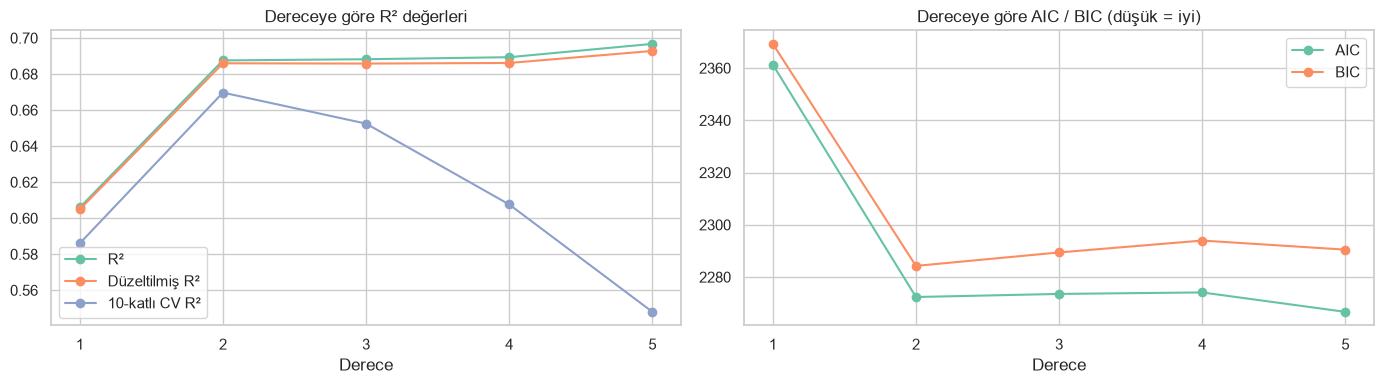

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
karsilastirma[["R²", "Düzeltilmiş R²", "10-katlı CV R²"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Dereceye göre R² değerleri")
axes[0].set_xticks(karsilastirma.index)
karsilastirma[["AIC", "BIC"]].plot(marker="o", ax=axes[1])
axes[1].set_title("Dereceye göre AIC / BIC (düşük = iyi)")
axes[1].set_xticks(karsilastirma.index)
plt.tight_layout()
plt.show()

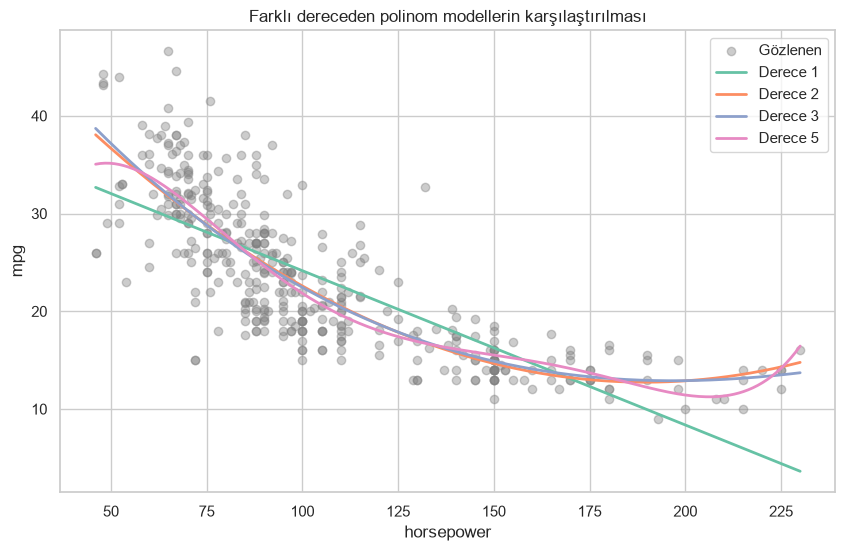

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, alpha=0.4, color="gray", label="Gözlenen")
x_cizgi = np.linspace(x.min(), x.max(), 300)
for k in [1, 2, 3, 5]:
    katsayi = np.polyfit(x, y, k)
    ax.plot(x_cizgi, np.polyval(katsayi, x_cizgi), linewidth=2, label=f"Derece {k}")
ax.set_xlabel("horsepower")
ax.set_ylabel("mpg")
ax.set_title("Farklı dereceden polinom modellerin karşılaştırılması")
ax.legend()
plt.show()

In [21]:
DERECE = 2
model = polinom_ols(x, y, DERECE)
print(model.summary(xname=["β0 (sabit)", "β1 (x)", "β2 (x²)"], yname="mpg"))

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     428.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.40e-99
Time:                        21:22:23   Log-Likelihood:                -1133.2
No. Observations:                 392   AIC:                             2272.
Df Residuals:                     389   BIC:                             2284.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
β0 (sabit)    56.9001      1.800     31.604      0.0

In [22]:
katsayilar = pd.DataFrame({
    "Katsayı": model.params,
    "Std. Hata": model.bse,
    "t": model.tvalues,
    "p-değeri": model.pvalues,
    "%95 GA Alt": model.conf_int()[:, 0],
    "%95 GA Üst": model.conf_int()[:, 1],
}, index=["β0 (sabit)", "β1 (horsepower)", "β2 (horsepower²)"])
pd.set_option("display.float_format", "{:.6f}".format)
display(katsayilar)
pd.set_option("display.float_format", "{:.4f}".format)

b0, b1, b2 = model.params
print(f"\nRegresyon denklemi:\n  mpg = {b0:.4f} {b1:+.4f}·hp {b2:+.6f}·hp²")

,Katsayı,Std. Hata,t,p-değeri,%95 GA Alt,%95 GA Üst
β0 (sabit),56.900100,1.800427,31.603673,0.000000,53.360315,60.439885
β1 (horsepower),-0.466190,0.031125,-14.978164,0.000000,-0.527383,-0.404996
β2 (horsepower²),0.001231,0.000122,10.080093,0.000000,0.000991,0.001471



Regresyon denklemi:
  mpg = 56.9001 -0.4662·hp +0.001231·hp²


In [23]:
X_mat = np.column_stack([np.ones_like(x), x, x ** 2])
beta = np.linalg.solve(X_mat.T @ X_mat, X_mat.T @ y)

sk_model = make_pipeline(PolynomialFeatures(DERECE, include_bias=False), LinearRegression()).fit(X_2d, y)
lr = sk_model.named_steps["linearregression"]

pd.set_option("display.float_format", "{:.6f}".format)
display(pd.DataFrame({
    "statsmodels": model.params,
    "(XᵀX)⁻¹Xᵀy": beta,
    "scikit-learn": np.r_[lr.intercept_, lr.coef_],
    "numpy.polyfit": np.polyfit(x, y, DERECE)[::-1],
}, index=["β0", "β1", "β2"]))
pd.set_option("display.float_format", "{:.4f}".format)

,statsmodels,(XᵀX)⁻¹Xᵀy,scikit-learn,numpy.polyfit
β0,56.900100,56.900100,56.900100,56.900100
β1,-0.466190,-0.466190,-0.466190,-0.466190
β2,0.001231,0.001231,0.001231,0.001231


In [24]:
y_tahmin = model.fittedvalues
R = np.corrcoef(y, y_tahmin)[0, 1]
r_dogrusal = stats.pearsonr(x, y)[0]

print(f"R (gözlenen - tahmin korelasyonu) : {R:.4f}")
print(f"√R²                                : {np.sqrt(model.rsquared):.4f}")
print(f"Karşılaştırma - doğrusal r (x, y)  : {r_dogrusal:.4f}  (|r| = {abs(r_dogrusal):.4f})")

R (gözlenen - tahmin korelasyonu) : 0.8292
√R²                                : 0.8292
Karşılaştırma - doğrusal r (x, y)  : -0.7784  (|r| = 0.7784)


In [25]:
def r_yorum(r):
    r = abs(r)
    if r >= 0.9: return "çok güçlü"
    if r >= 0.7: return "güçlü"
    if r >= 0.5: return "orta"
    if r >= 0.3: return "zayıf"
    return "çok zayıf"

print(f"R = {R:.4f} → model ile gözlenen değerler arasında {r_yorum(R)} bir ilişki vardır.")

R = 0.8292 → model ile gözlenen değerler arasında güçlü bir ilişki vardır.


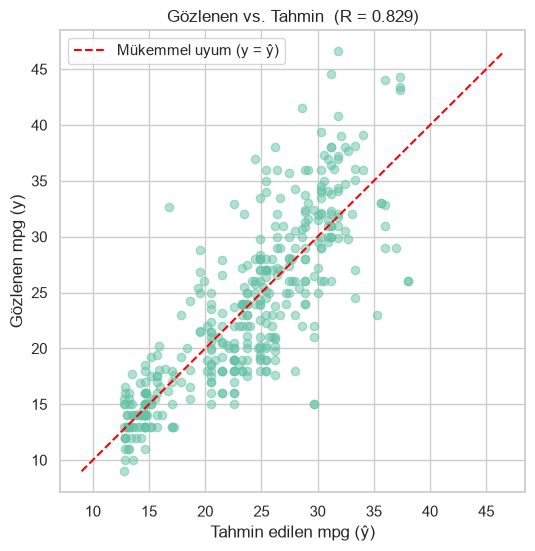

In [26]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_tahmin, y, alpha=0.5)
sinir = [min(y.min(), y_tahmin.min()), max(y.max(), y_tahmin.max())]
ax.plot(sinir, sinir, "r--", label="Mükemmel uyum (y = ŷ)")
ax.set_xlabel("Tahmin edilen mpg (ŷ)")
ax.set_ylabel("Gözlenen mpg (y)")
ax.set_title(f"Gözlenen vs. Tahmin  (R = {R:.3f})")
ax.legend()
plt.show()

In [27]:
artik = model.resid
pd.Series({
    "MAE (ortalama mutlak hata)": mean_absolute_error(y, y_tahmin),
    "RMSE": np.sqrt(mean_squared_error(y, y_tahmin)),
    "Tahminin standart hatası (s)": np.sqrt(model.mse_resid),
    "Ortalama mutlak yüzde hata (%)": np.mean(np.abs(artik / y)) * 100,
    "F istatistiği": model.fvalue,
    "F testi p-değeri": model.f_pvalue,
}).to_frame("Değer")

,Değer
MAE (ortalama mutlak hata),3.2495
RMSE,4.3572
Tahminin standart hatası (s),4.3739
Ortalama mutlak yüzde hata (%),14.1519
F istatistiği,428.0176
F testi p-değeri,0.0000


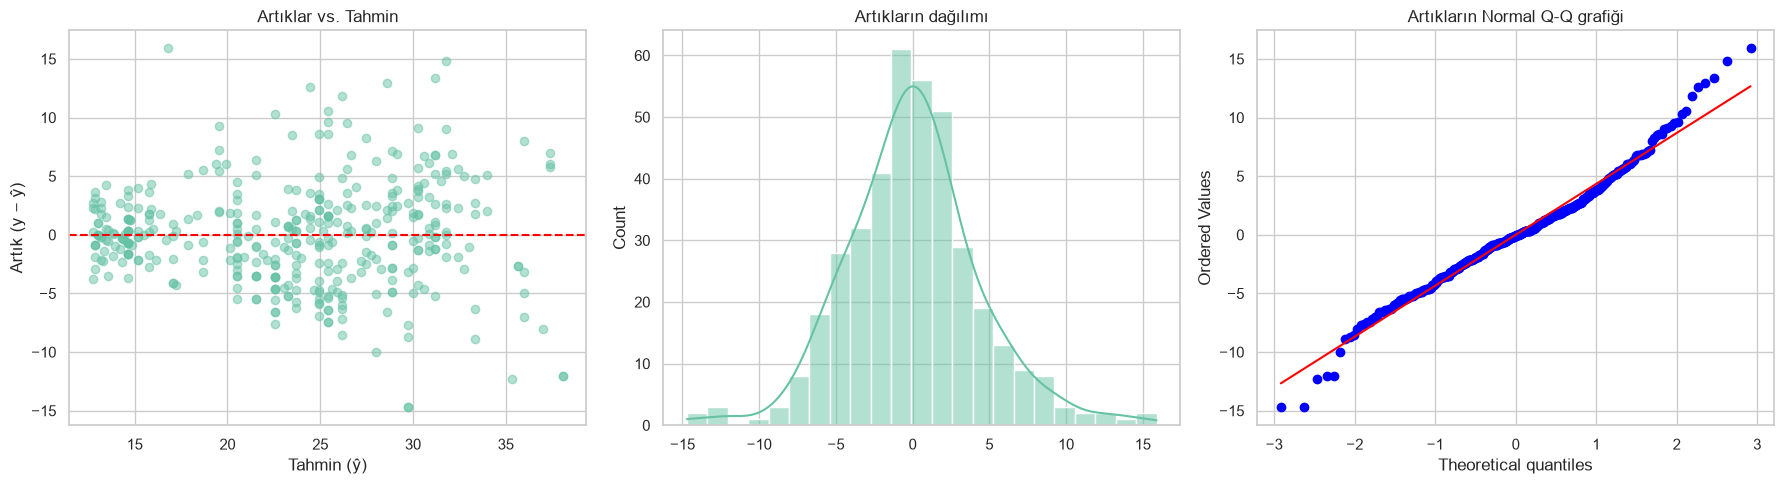

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_tahmin, artik, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Tahmin (ŷ)")
axes[0].set_ylabel("Artık (y − ŷ)")
axes[0].set_title("Artıklar vs. Tahmin")

sns.histplot(artik, kde=True, ax=axes[1])
axes[1].set_title("Artıkların dağılımı")

stats.probplot(artik, dist="norm", plot=axes[2])
axes[2].set_title("Artıkların Normal Q-Q grafiği")
plt.tight_layout()
plt.show()

In [29]:
SST = np.sum((y - y.mean()) ** 2)
SSR = np.sum((y_tahmin - y.mean()) ** 2)
SSE = np.sum((y - y_tahmin) ** 2)
R2 = SSR / SST
n, p = len(y), DERECE
R2_duz = 1 - (1 - R2) * (n - 1) / (n - p - 1)

print(f"SST (toplam değişim)       = {SST:,.2f}")
print(f"SSR (açıklanan değişim)    = {SSR:,.2f}")
print(f"SSE (açıklanamayan değişim)= {SSE:,.2f}")
print(f"SSR + SSE                  = {SSR + SSE:,.2f}")
print()
print(f"R² = SSR / SST       = {R2:.4f}")
print(f"R² = 1 − SSE / SST   = {1 - SSE / SST:.4f}")
print(f"R² (sklearn)         = {r2_score(y, sk_model.predict(X_2d)):.4f}")
print(f"Düzeltilmiş R²       = {R2_duz:.4f}")
print()
print(f"→ horsepower (polinom modeliyle), mpg'deki toplam değişimin %{R2 * 100:.2f}'sini açıklamaktadır.")
print(f"→ Kalan %{(1 - R2) * 100:.2f}'lik değişim modelde yer almayan diğer faktörlerden (ağırlık, model yılı vb.) kaynaklanır.")

SST (toplam değişim)       = 23,818.99
SSR (açıklanan değişim)    = 16,376.96
SSE (açıklanamayan değişim)= 7,442.03
SSR + SSE                  = 23,818.99

R² = SSR / SST       = 0.6876
R² = 1 − SSE / SST   = 0.6876
R² (sklearn)         = 0.6876
Düzeltilmiş R²       = 0.6860

→ horsepower (polinom modeliyle), mpg'deki toplam değişimin %68.76'sini açıklamaktadır.
→ Kalan %31.24'lik değişim modelde yer almayan diğer faktörlerden (ağırlık, model yılı vb.) kaynaklanır.


In [30]:
anova = pd.DataFrame({
    "Kareler Toplamı": [SSR, SSE, SST],
    "Serbestlik Derecesi": [p, n - p - 1, n - 1],
}, index=["Regresyon", "Hata (Artık)", "Toplam"])
anova["Kareler Ortalaması"] = anova["Kareler Toplamı"] / anova["Serbestlik Derecesi"]
anova.loc["Toplam", "Kareler Ortalaması"] = np.nan
F = anova.loc["Regresyon", "Kareler Ortalaması"] / anova.loc["Hata (Artık)", "Kareler Ortalaması"]
anova.loc["Regresyon", "F"] = F
anova.loc["Regresyon", "p-değeri"] = stats.f.sf(F, p, n - p - 1)
print("ANOVA Tablosu")
anova

ANOVA Tablosu


,Kareler Toplamı,Serbestlik Derecesi,Kareler Ortalaması,F,p-değeri
Regresyon,16376.9641,2,8188.4820,428.0176,0.0000
Hata (Artık),7442.0294,389,19.1312,NaN,NaN
Toplam,23818.9935,391,NaN,NaN,NaN


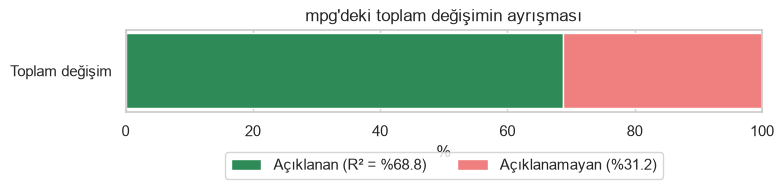

In [31]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.barh(["Toplam değişim"], [R2 * 100], color="seagreen", label=f"Açıklanan (R² = %{R2 * 100:.1f})")
ax.barh(["Toplam değişim"], [(1 - R2) * 100], left=[R2 * 100], color="lightcoral",
        label=f"Açıklanamayan (%{(1 - R2) * 100:.1f})")
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=2)
ax.set_title("mpg'deki toplam değişimin ayrışması")
plt.tight_layout()
plt.show()

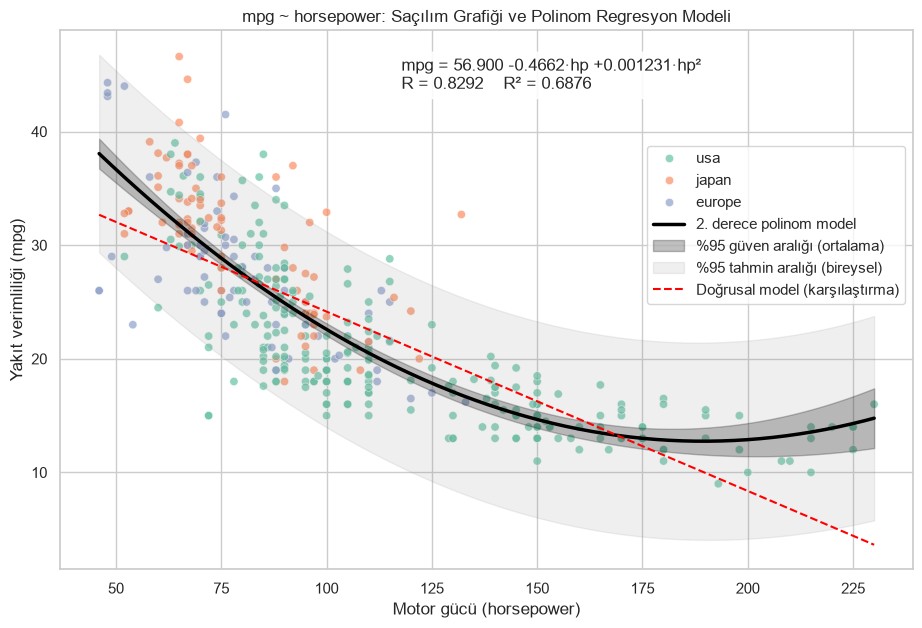

In [32]:
x_cizgi = np.linspace(x.min(), x.max(), 300)
X_cizgi = sm.add_constant(np.column_stack([x_cizgi, x_cizgi ** 2]))
tahmin = model.get_prediction(X_cizgi).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=veri, x="horsepower", y="mpg", hue="origin", alpha=0.7, ax=ax)
ax.plot(x_cizgi, tahmin["mean"], color="black", linewidth=2.5, label="2. derece polinom model")
ax.fill_between(x_cizgi, tahmin["mean_ci_lower"], tahmin["mean_ci_upper"], color="black", alpha=0.25,
                label="%95 güven aralığı (ortalama)")
ax.fill_between(x_cizgi, tahmin["obs_ci_lower"], tahmin["obs_ci_upper"], color="gray", alpha=0.12,
                label="%95 tahmin aralığı (bireysel)")
ax.plot(x_cizgi, np.polyval(np.polyfit(x, y, 1), x_cizgi), "r--", linewidth=1.5, label="Doğrusal model (karşılaştırma)")

ax.text(0.40, 0.95, f"mpg = {b0:.3f} {b1:+.4f}·hp {b2:+.6f}·hp²\nR = {R:.4f}    R² = {R2:.4f}",
        transform=ax.transAxes, fontsize=12, va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
ax.set_xlabel("Motor gücü (horsepower)")
ax.set_ylabel("Yakıt verimliliği (mpg)")
ax.set_title("mpg ~ horsepower: Saçılım Grafiği ve Polinom Regresyon Modeli")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.8))
plt.show()

In [33]:
ornek_hp = np.array([50, 75, 100, 150, 200])
ornek = model.get_prediction(sm.add_constant(np.column_stack([ornek_hp, ornek_hp ** 2]))).summary_frame()
ornek.index = ornek_hp
ornek.index.name = "horsepower"
ornek = ornek.rename(columns={"mean": "Tahmini mpg", "obs_ci_lower": "Tahmin Aralığı Alt", "obs_ci_upper": "Tahmin Aralığı Üst"})
ornek[["Tahmini mpg", "Tahmin Aralığı Alt", "Tahmin Aralığı Üst"]]

,Tahmini mpg,Tahmin Aralığı Alt,Tahmin Aralığı Üst
horsepower,,,
50,36.6670,27.9876,45.3463
75,28.8576,20.2395,37.4758
100,22.5865,13.9705,31.2025
150,14.6587,6.0273,23.2902
200,12.8836,4.1612,21.6061


In [34]:
for hp in [50, 100, 150]:
    print(f"hp = {hp:3d} iken 1 hp artış mpg'yi {b1 + 2 * b2 * hp:+.3f} değiştirir")
tepe = -b1 / (2 * b2)
print(f"\nParabolün minimum (tepe) noktası: hp ≈ {tepe:.1f}, mpg ≈ {b0 + b1 * tepe + b2 * tepe ** 2:.2f}")
print(f"Veride hp > {tepe:.0f} olan araç sayısı: {(x > tepe).sum()} / {len(x)}")

hp =  50 iken 1 hp artış mpg'yi -0.343 değiştirir
hp = 100 iken 1 hp artış mpg'yi -0.220 değiştirir
hp = 150 iken 1 hp artış mpg'yi -0.097 değiştirir

Parabolün minimum (tepe) noktası: hp ≈ 189.4, mpg ≈ 12.75
Veride hp > 189 olan araç sayısı: 17 / 392
